## Немного переводов
Протестируем разные небольшие модельки для перевода с английского на русский.
В качестве метрик будем использовать

1. **BLEU**
2. **CHRF**
3. **COMET**

В качестве моделей будем использовать следующее. Если используется general-purpose LLM, в промпт буду добавлять условие на длину перевода (+7-13%, см data-and-models-2.ipynb).

1. **Helsinki-NLP/opus-mt-en-ru**
2. **google_gemma-3-4b-it-Q4**
3. **nllb-200-1.3B-ct2_int8**
4. **Llama-3.2-3B-Instruct-Q8_0**
5. **facebook/wmt19-en-ru**
6. **t5_translate_en_ru_zh_large_1024**

Тесты гонялись на моей личной GTX 1060, все модели целиком влезали в память. Потребеление VRAM на 1-4 ~4GB, на 5-6 ~6GB

In [1]:
import gc

import sacrebleu
import torch
from comet import download_model, load_from_checkpoint
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"

data = load_dataset("facebook/flores", "eng_Latn-rus_Cyrl", split="devtest")

In [2]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

translator = "Helsinki-NLP/opus-mt-en-ru"
tok = AutoTokenizer.from_pretrained(translator)

mt = AutoModelForSeq2SeqLM.from_pretrained(translator).to(device)


def translate_batch(batch):
    inputs = tok(
        batch["sentence_eng_Latn"],
        return_tensors="pt",
        padding=True,
        truncation=True,
    ).to(device)

    with torch.no_grad():
        prediction_tokens = mt.generate(**inputs)

    decoded_translations = tok.batch_decode(prediction_tokens, skip_special_tokens=True)

    return {"sentence_rus_opus_mt_en_ru": decoded_translations}


data = data.map(translate_batch, batched=True, batch_size=32)

del mt
# Release evaluator GPU memory before the synthesis subprocess.
if "asr" in globals():
    del asr
if "encoder" in globals():
    del encoder
torch.cuda.empty_cache()

Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

In [3]:
from huggingface_hub import hf_hub_download
from llama_cpp import Llama

gemma_path = hf_hub_download(
    repo_id="bartowski/google_gemma-3-4b-it-GGUF", filename="google_gemma-3-4b-it-Q4_K_M.gguf"
)


llm = Llama(model_path=gemma_path, n_ctx=2048, n_gpu_layers=-1, verbose=False)


def translate_using_gemma3_4b(item):
    text = item["sentence_eng_Latn"]

    prompt = (
        f"Переведи следующий текст на русский. "
        "Выведи ТОЛЬКО перевод и ничего лишнего. "
        "Перевод должен быть где-то на 7-11 процентов длиннее оригинала:\n\n"
        f"{text}"
    )

    response = llm.create_chat_completion(
        messages=[{"role": "user", "content": prompt}], temperature=0.2, max_tokens=512
    )

    res = response["choices"][0]["message"]["content"].strip()

    return {"sentence_rus_gemma3_4b": res}


data = data.map(translate_using_gemma3_4b)

del llm
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

llama_kv_cache_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)


Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

In [4]:
import ctranslate2
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer

model_dir = snapshot_download(
    repo_id="KomorebiAI/nllb-200-1.3B-ct2", allow_patterns=["*.bin", "*.json", "*.txt"]
)

tokenizer = AutoTokenizer.from_pretrained(model_dir, src_lang="eng_Latn")
translator = ctranslate2.Translator(model_dir, device=device, compute_type="int8")


def translate_using_nllb_1_3b(item):
    texts = item["sentence_eng_Latn"]

    encoded_batch = tokenizer.batch_encode_plus(texts, add_special_tokens=True)["input_ids"]
    source_tokens = [tokenizer.convert_ids_to_tokens(ids) for ids in encoded_batch]

    target_prefixes = [["rus_Cyrl"] for _ in range(len(texts))]

    results = translator.translate_batch(
        source_tokens, target_prefix=target_prefixes, max_batch_size=32, beam_size=4
    )

    translated_texts = []
    for res in results:
        hyp = res.hypotheses[0]
        target_tokens = hyp[1:] if (len(hyp) > 0 and hyp[0] == "rus_Cyrl") else hyp

        decoded_text = tokenizer.decode(tokenizer.convert_tokens_to_ids(target_tokens)).strip()
        translated_texts.append(decoded_text)

    return {"sentence_rus_nllb_1_3b_int8": translated_texts}


data = data.map(translate_using_nllb_1_3b, batched=True, batch_size=32)

del translator
del tokenizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

The tokenizer you are loading from '/home/wandrl/.cache/huggingface/hub/models--KomorebiAI--nllb-200-1.3B-ct2/snapshots/66c1700220528430cdd8a119ee46115d214665a2' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Parameter 'function'=<function translate_using_nllb_1_3b at 0x78adb75e6f20> of the transform datasets.arrow_dataset.Dataset._map_single couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only showed once. Subsequent hashing failures won't be showed.
Parameter 'functi

Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

In [5]:
from huggingface_hub import hf_hub_download
from llama_cpp import Llama

llama_path = hf_hub_download(
    repo_id="bartowski/Llama-3.2-3B-Instruct-GGUF",
    filename="Llama-3.2-3B-Instruct-Q8_0.gguf",
)

llm = Llama(model_path=llama_path, n_ctx=2048, n_gpu_layers=-1, verbose=False)


def translate_using_llama32_3b_q8(item):
    text = item["sentence_eng_Latn"]

    prompt = (
        "Переведи следующий текст на русский. "
        "Выведи ТОЛЬКО перевод и ничего лишнего. "
        "Перевод должен быть где-то на 7-11 процентов длиннее оригинала:\n\n"
        f"{text}"
    )

    response = llm.create_chat_completion(
        messages=[{"role": "user", "content": prompt}], temperature=0.2, max_tokens=512
    )

    res = response["choices"][0]["message"]["content"].strip()

    return {"sentence_rus_llama32_3b": res}


data = data.map(translate_using_llama32_3b_q8)

del llm
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

In [6]:
from transformers import FSMTForConditionalGeneration, FSMTTokenizer

translator = "facebook/wmt19-en-ru"

tok = FSMTTokenizer.from_pretrained(translator)
mt = FSMTForConditionalGeneration.from_pretrained(translator, torch_dtype=torch.float16).to(device)


def translate_batch(batch):
    inputs = tok(
        batch["sentence_eng_Latn"],
        return_tensors="pt",
        padding=True,
        truncation=True,
    ).to(device)

    with torch.no_grad():
        prediction_tokens = mt.generate(**inputs, max_length=512)

    decoded_translations = tok.batch_decode(prediction_tokens, skip_special_tokens=True)

    return {"sentence_rus_wmt19_en_ru": decoded_translations}


data = data.map(translate_batch, batched=True, batch_size=32)


del mt
del tok
if "asr" in globals():
    del asr
if "encoder" in globals():
    del encoder

gc.collect()
torch.cuda.empty_cache()

`torch_dtype` is deprecated! Use `dtype` instead!


Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

In [7]:
from transformers import T5ForConditionalGeneration, T5Tokenizer

translator = "utrobinmv/t5_translate_en_ru_zh_large_1024"

tok = T5Tokenizer.from_pretrained(translator)
mt = T5ForConditionalGeneration.from_pretrained(translator, torch_dtype=torch.float16).to(device)


def translate_batch(batch):
    prefixed_texts = ["translate to ru: " + text for text in batch["sentence_eng_Latn"]]

    inputs = tok(
        prefixed_texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
    ).to(device)

    with torch.no_grad():
        prediction_tokens = mt.generate(**inputs, max_length=512)

    decoded_translations = tok.batch_decode(prediction_tokens, skip_special_tokens=True)

    return {"sentence_rus_t5_large": decoded_translations}


data = data.map(translate_batch, batched=True, batch_size=32)

del mt
del tok
if "asr" in globals():
    del asr
if "encoder" in globals():
    del encoder

gc.collect()
torch.cuda.empty_cache()

Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

Both `max_new_tokens` (=1024) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

In [8]:
examples = [
    "sentence_eng_Latn",
    "sentence_rus_Cyrl",
    "sentence_rus_opus_mt_en_ru",
    "sentence_rus_gemma3_4b",
    "sentence_rus_nllb_1_3b_int8",
    "sentence_rus_llama32_3b",
    "sentence_rus_wmt19_en_ru",
    "sentence_rus_t5_large",
]

inidces_to_check = [0, 15, 139, 256, 452]

for idx in inidces_to_check:
    print("Index #", idx)
    for key in examples:
        if key in data.column_names:
            print(key, ": ", data[key][idx])

Index # 0
sentence_eng_Latn :  "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
sentence_rus_Cyrl :  "Теперь у нас есть четырёхмесячные мыши, у которых больше нет диабета", — добавил он.
sentence_rus_opus_mt_en_ru :  "У нас есть 4-месячные мыши, которые не диабетичны, которые раньше были диабетиками", добавил он.
sentence_rus_gemma3_4b :  "Теперь у нас есть мыши, которым 4 месяца, и которые ранее страдали от диабета, но теперь уже не являются диабетическими," — добавил он.
sentence_rus_nllb_1_3b_int8 :  "У нас теперь есть 4-месячные мыши, которые не страдают диабетом, которые раньше были диабетиками", - добавил он.
sentence_rus_llama32_3b :  Нам сейчас 4-месячные мыши, которые не имеют диабета, а раньше были диабетиками.
sentence_rus_wmt19_en_ru :  "У нас сейчас есть 4-месячные дети, которые не болеют диабетом, а раньше были диабетом", - добавил он.
sentence_rus_t5_large :  «Теперь у нас есть 4-месячные мыши, которые не являются диабетиками и ран

In [9]:
model_path = download_model("Unbabel/wmt22-comet-da")
model = load_from_checkpoint(model_path)

use_gpu = 1 if torch.cuda.is_available() else 0


def BLEU_score(data, column):
    bleu = sacrebleu.corpus_bleu(data[column], [data["sentence_rus_Cyrl"]])
    return bleu


def CHRF_score(data, column):
    chrf = sacrebleu.corpus_chrf(data[column], [data["sentence_rus_Cyrl"]])
    return chrf


def COMET_score(data, column):

    comet_input = [
        {"src": src, "mt": mt, "ref": ref}
        for src, mt, ref in zip(data["sentence_eng_Latn"], data[column], data["sentence_rus_Cyrl"])
    ]

    model_output = model.predict(comet_input, batch_size=8, gpus=use_gpu)
    system_score = model_output.system_score

    if "model_output" in locals():
        del model_output
    if "comet_input" in locals():
        del comet_input

    return system_score


result = {}


def score_column(data, column, name):
    bleu_score = BLEU_score(data, column).score
    chrf_score = CHRF_score(data, column).score
    comet_score = COMET_score(data, column)

    result[name] = {
        "bleu": bleu_score,
        "chrf": chrf_score,
        "comet": comet_score,
    }

    return


score_column(data, "sentence_rus_Cyrl", "baseline")
score_column(data, "sentence_rus_opus_mt_en_ru", "Helsinki-NLP/opus-mt-en-ru")
score_column(data, "sentence_rus_gemma3_4b", "google_gemma-3-4b-it-Q4")
score_column(data, "sentence_rus_nllb_1_3b_int8", "nllb-200-1.3B-ct2_int8")
score_column(data, "sentence_rus_llama32_3b", "Llama-3.2-3B-Instruct-Q8_0")
score_column(data, "sentence_rus_wmt19_en_ru", "facebook/wmt19-en-ru")
score_column(data, "sentence_rus_t5_large", "t5_translate_en_ru_zh_large_1024")

del model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Lightning automatically upgraded your loaded checkpoint from v1.8.3.post1 to v2.6.6. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../../.cache/huggingface/hub/models--Unbabel--wmt22-comet-da/snapshots/2760a223ac957f30acfb18c8aa649b01cf1d75f2/checkpoints/model.ckpt`
Encoder model frozen.
/home/wandrl/python_envs/main_env/lib/python3.12/site-packages/pytorch_lightning/core/saving.py:216: Found keys that are not in the model state dict but in the checkpoint: ['encoder.model.embeddings.position_ids']
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) 

║ Model Configuration              ║     BLEU     ║     CHRF     ║    COMET     ║
║ baseline                         ║   100.0000   ║   100.0000   ║    0.9666    ║
║ Helsinki-NLP/opus-mt-en-ru       ║   25.4152    ║   53.5197    ║    0.8473    ║
║ google_gemma-3-4b-it-Q4          ║   13.8909    ║   50.2669    ║    0.8636    ║
║ nllb-200-1.3B-ct2_int8           ║   29.8198    ║   56.6203    ║    0.8828    ║
║ Llama-3.2-3B-Instruct-Q8_0       ║   18.6328    ║   45.0533    ║    0.7811    ║
║ facebook/wmt19-en-ru             ║   25.7779    ║   54.6925    ║    0.8221    ║
║ t5_translate_en_ru_zh_large_1024 ║   29.8086    ║   57.8211    ║    0.8769    ║


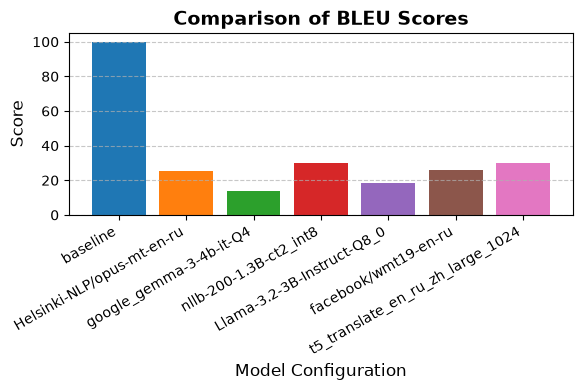

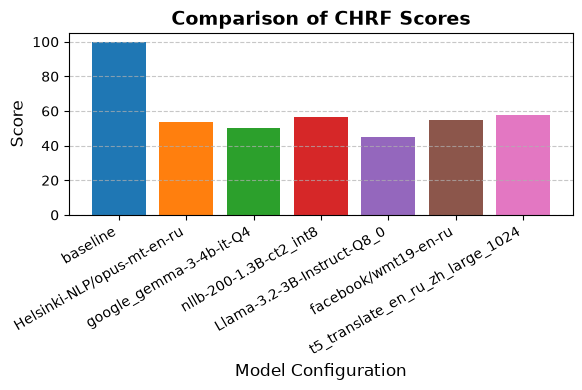

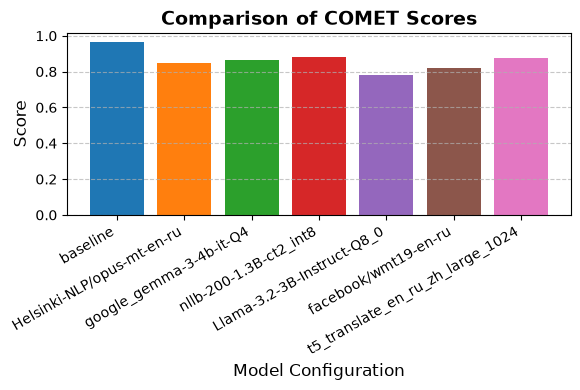

In [10]:
import matplotlib.pyplot as plt

models = list(result.keys())
metrics = list(result[models[0]].keys())

model_col_width = max(max(len(m) for m in models), 19)
metric_col_width = 12

header = (
    f"║ {'Model Configuration':<{model_col_width}} ║ "
    + " ║ ".join(f"{m.upper():^{metric_col_width}}" for m in metrics)
    + " ║"
)

print(header)

for model in models:
    row_str = f"║ {model:<{model_col_width}} ║ "
    row_values = []
    for metric in metrics:
        val = result[model][metric]
        val_str = f"{val:.4f}" if isinstance(val, (int, float)) else str(val)
        row_values.append(f"{val_str:^{metric_col_width}}")
    row_str += " ║ ".join(row_values) + " ║"
    print(row_str)


colors = plt.cm.tab10(range(len(models)))
for metric in metrics:
    scores = [result[model][metric] for model in models]

    plt.figure(figsize=(6, 4))

    plt.bar(models, scores, color=colors)

    plt.title(f"Comparison of {metric.upper()} Scores", fontsize=14, weight="bold")
    plt.ylabel("Score", fontsize=12)
    plt.xlabel("Model Configuration", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## Что по итогу
Локально развернутые LLM можно использовать, но качество перевода ощутимо хуже, чем у моделей заточенных на eng - rus перевод. Плюс они сильно медленней. Последний пункт наверняка решается батчингом, однако качество, кроме как использования более тяжелой модели, вряд-ли получится выправить иначе.

Для нашего проекта я бы рекомендовал использовать **nllb-200-1.3B-ct2_int8** - лучшая скорость и один из лучших переводов. Второй кандидат - **t5_translate_en_ru_zh_large_1024** - уровень перевода примерно такой же, но ощутимо медленнее.

Есть еще один вариант - использовать внешнюю **LLM** с системным промптом. Вариант скорее всего будет лучшем в плане качества перевода и соотвествия длины, но не бесплатным. 